# Kalman Filter Techniques and Statistical Arbitrage

**Updated with yfinance data** | Adapted from [QuantInsti Blog](https://blog.quantinsti.com/kalman-filter-techniques-statistical-arbitrage-china-futures-market-python/)

Original tickers from shared data (Chinese futures):  
`M, SR, FG, CU, SN, NI, RM, AG, OI, CF, HC, J, I, TA, PB, AU, RB, V, JD, MA, TC, A, ZN, SF, P, C, BU, PP, JM, RU, AL, Y, CS, L`

These exact China futures contracts are not available on yfinance. Closest liquid proxies are used below.


## Import libraries

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
from pykalman import KalmanFilter
import ffn
import warnings
warnings.filterwarnings('ignore')

# Better colors
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
COLORS = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#3B1F2B', '#44BBA4', '#E94F37', '#393E41']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=COLORS)
%matplotlib inline


## Read data of all contracts

In [2]:
# Original tickers (China futures) — not on yfinance
original_tickers = [
    'M', 'SR', 'FG', 'CU', 'SN', 'NI', 'RM', 'AG', 'OI', 'CF',
    'HC', 'J', 'I', 'TA', 'PB', 'AU', 'RB', 'V', 'JD', 'MA',
    'TC', 'A', 'ZN', 'SF', 'P', 'C', 'BU', 'PP', 'JM', 'RU',
    'AL', 'Y', 'CS', 'L'
]
print(f"Original tickers ({len(original_tickers)}): {original_tickers}")

# Closest yfinance futures proxies
proxy_map = {
    'CL': 'CL=F', 'BZ': 'BZ=F', 'GC': 'GC=F', 'SI': 'SI=F',
    'HG': 'HG=F', 'NG': 'NG=F', 'ZC': 'ZC=F', 'ZS': 'ZS=F',
    'KC': 'KC=F', 'CT': 'CT=F', 'ZW': 'ZW=F', 'LE': 'LE=F'
}
tickers = list(proxy_map.values())
print(f"\nDownloading {len(tickers)} yfinance proxies...")
raw = yf.download(tickers, start='2018-01-01', end='2026-11-01', progress=False, auto_adjust=True)['Close']
raw.columns = [k for k, v in proxy_map.items() if v in raw.columns]
data = raw.dropna(how='all').ffill().dropna()
print(f"Shape: {data.shape} | {data.index[0].date()} → {data.index[-1].date()}")
data.tail(3)


Original tickers (34): ['M', 'SR', 'FG', 'CU', 'SN', 'NI', 'RM', 'AG', 'OI', 'CF', 'HC', 'J', 'I', 'TA', 'PB', 'AU', 'RB', 'V', 'JD', 'MA', 'TC', 'A', 'ZN', 'SF', 'P', 'C', 'BU', 'PP', 'JM', 'RU', 'AL', 'Y', 'CS', 'L']



Shape: (2223, 12) | 2018-01-02 → 2026-10-30


,CL,BZ,GC,SI,HG,NG,ZC,ZS,KC,CT,ZW,LE
Date,,,,,,,,,,,,
2026-10-28,115.320000,102.779999,78.150002,4051.600098,6.6415,286.750000,227.375000,2.817,53.457001,451.75,1224.50,599.00
2026-10-29,114.879997,102.000000,78.500000,4031.399902,6.5810,285.450012,227.274994,2.952,52.191002,451.25,1219.75,603.75
2026-10-30,117.639999,104.120003,77.830002,3898.899902,6.4585,287.200012,224.000000,2.898,49.097000,447.75,1222.25,603.50


## Find cointegrated pairs

In [3]:
def find_cointegrated_pairs(dataframe, critial_level=0.05):
    n = dataframe.shape[1]
    keys = dataframe.columns
    pairs = []
    for i in range(n):
        for j in range(i+1, n):
            score, pvalue, _ = coint(dataframe.iloc[:, i], dataframe.iloc[:, j])
            if pvalue < critial_level:
                pairs.append([keys[i], keys[j], pvalue])
    return pd.DataFrame(pairs, columns=['Asset1', 'Asset2', 'p-value']).sort_values('p-value')

pairs = find_cointegrated_pairs(data)
print(f"Found {len(pairs)} cointegrated pairs")
pairs


Found 8 cointegrated pairs


,Asset1,Asset2,p-value
4,ZS,LE,0.000675
6,CT,LE,0.002763
2,GC,LE,0.003823
3,ZS,CT,0.007106
7,ZW,LE,0.027562
1,GC,CT,0.039198
0,CL,BZ,0.041680
5,CT,ZW,0.049018


## Create functions

In [4]:
def hurst(ts):
    lags = range(2, 100)
    tau = [np.sqrt(np.std(np.subtract(ts[lag:], ts[:-lag]))) for lag in lags]
    poly = np.polyfit(np.log(lags), np.log(tau), 1)
    return poly[0] * 2.0

def half_life(spread):
    spread_lag = spread.shift(1).bfill()
    spread_ret = spread - spread_lag
    spread_lag2 = sm.add_constant(spread_lag)
    model = sm.OLS(spread_ret, spread_lag2).fit()
    hl = int(round(-np.log(2) / model.params.iloc[1], 0))
    return max(hl, 1)

def KalmanFilterAverage(x):
    kf = KalmanFilter(transition_matrices=[1], observation_matrices=[1],
                      initial_state_mean=0, initial_state_covariance=1,
                      observation_covariance=1, transition_covariance=0.01)
    state_means, _ = kf.filter(x.values)
    return pd.Series(state_means.flatten(), index=x.index)

def KalmanFilterRegression(x, y):
    delta = 1e-3
    trans_cov = delta / (1 - delta) * np.eye(2)
    obs_mat = np.expand_dims(np.vstack([[x], [np.ones(len(x))]]).T, axis=1)
    kf = KalmanFilter(n_dim_obs=1, n_dim_state=2,
                      initial_state_mean=[0, 0],
                      initial_state_covariance=np.ones((2, 2)),
                      transition_matrices=np.eye(2),
                      observation_matrices=obs_mat,
                      observation_covariance=2,
                      transition_covariance=trans_cov)
    state_means, _ = kf.filter(y.values)
    return state_means

def backtest(s1, s2, x, y, entryZscore=2, exitZscore=0):
    df1 = pd.DataFrame({'y': y, 'x': x}).dropna()
    state_means = KalmanFilterRegression(KalmanFilterAverage(df1['x']), KalmanFilterAverage(df1['y']))
    df1['hr'] = -state_means[:, 0]
    df1['spread'] = df1.y + (df1.x * df1.hr)
    halflife = half_life(df1['spread'])
    meanSpread = df1.spread.rolling(window=halflife).mean()
    stdSpread = df1.spread.rolling(window=halflife).std()
    df1['zScore'] = (df1.spread - meanSpread) / stdSpread

    df1['long entry'] = ((df1.zScore < -entryZscore) & (df1.zScore.shift(1) >= -entryZscore))
    df1['long exit'] = ((df1.zScore > -exitZscore) & (df1.zScore.shift(1) <= -exitZscore))
    df1['num units long'] = np.nan
    df1.loc[df1['long entry'], 'num units long'] = 1
    df1.loc[df1['long exit'], 'num units long'] = 0
    df1['num units long'] = df1['num units long'].ffill().fillna(0)

    df1['short entry'] = ((df1.zScore > entryZscore) & (df1.zScore.shift(1) <= entryZscore))
    df1['short exit'] = ((df1.zScore < exitZscore) & (df1.zScore.shift(1) >= exitZscore))
    df1['num units short'] = np.nan
    df1.loc[df1['short entry'], 'num units short'] = -1
    df1.loc[df1['short exit'], 'num units short'] = 0
    df1['num units short'] = df1['num units short'].ffill().fillna(0)

    df1['numUnits'] = df1['num units long'] + df1['num units short']
    df1['spread pct ch'] = df1['spread'].diff() / ((df1['x'].abs() * df1['hr'].abs()) + df1['y'])
    df1['port rets'] = df1['spread pct ch'] * df1['numUnits'].shift(1)
    df1['cum rets'] = (1 + df1['port rets'].fillna(0)).cumprod()

    try:
        sharpe = (df1['port rets'].mean() / df1['port rets'].std()) * np.sqrt(252)
    except:
        sharpe = 0.0
    return df1['cum rets'], sharpe, halflife


## Load data

In [5]:
# Train / test split (~70/30) — mirrors original in-sample / out-sample
split = int(len(data) * 0.70)
train = data.iloc[:split]
test = data.iloc[split:]
print(f"Train: {train.index[0].date()} → {train.index[-1].date()} ({len(train)} days)")
print(f"Test : {test.index[0].date()} → {test.index[-1].date()} ({len(test)} days)")
train.tail(3)


Train: 2018-01-02 → 2024-03-07 (1556 days)
Test : 2024-03-08 → 2026-10-30 (667 days)


,CL,BZ,GC,SI,HG,NG,ZC,ZS,KC,CT,ZW,LE
Date,,,,,,,,,,,,
2024-03-05,82.040001,78.150002,98.099998,2141.899902,3.8440,195.000000,188.000000,1.957,23.763000,413.5,1140.75,545.75
2024-03-06,82.959999,79.129997,99.139999,2158.199951,3.8705,194.449997,187.250000,1.929,24.271999,418.0,1140.25,521.25
2024-03-07,82.959999,78.930000,99.279999,2165.199951,3.9195,198.350006,188.725006,1.818,24.370001,426.0,1157.00,520.75


## Choose pairs for out-sample testing

In [6]:
# Select pairs with Sharpe > 0.5 and final equity > 1.105 (same thresholds as original)
list_sect = []
ret = pd.DataFrame()
for _, row in pairs.iterrows():
    s1, s2 = row['Asset1'], row['Asset2']
    name = f"{s1}-{s2}"
    try:
        tmp, sharpe, hl = backtest(s1, s2, train[s1], train[s2])
        if sharpe > 0.5 and tmp.iloc[-1] > 1.105:
            ret[name] = tmp
            list_sect.append((s1, s2, sharpe, hl, tmp.iloc[-1]))
    except Exception:
        continue

print(f"Pairs selected: {len(list_sect)}")
pd.DataFrame(list_sect, columns=['s1','s2','Sharpe','HalfLife','Final'])


Pairs selected: 3


,s1,s2,Sharpe,HalfLife,Final
0,ZS,LE,1.505238,62,7.224483
1,ZS,CT,1.145951,132,3.683778
2,GC,CT,0.901035,7,1.345145


## In sample backtesting

In [7]:
# In-sample results
if len(ret) > 0:
    ret.iloc[0] = 1
    ret.index = train.index[:len(ret)]
    ret.tail(3)
else:
    print("No pairs met selection criteria")


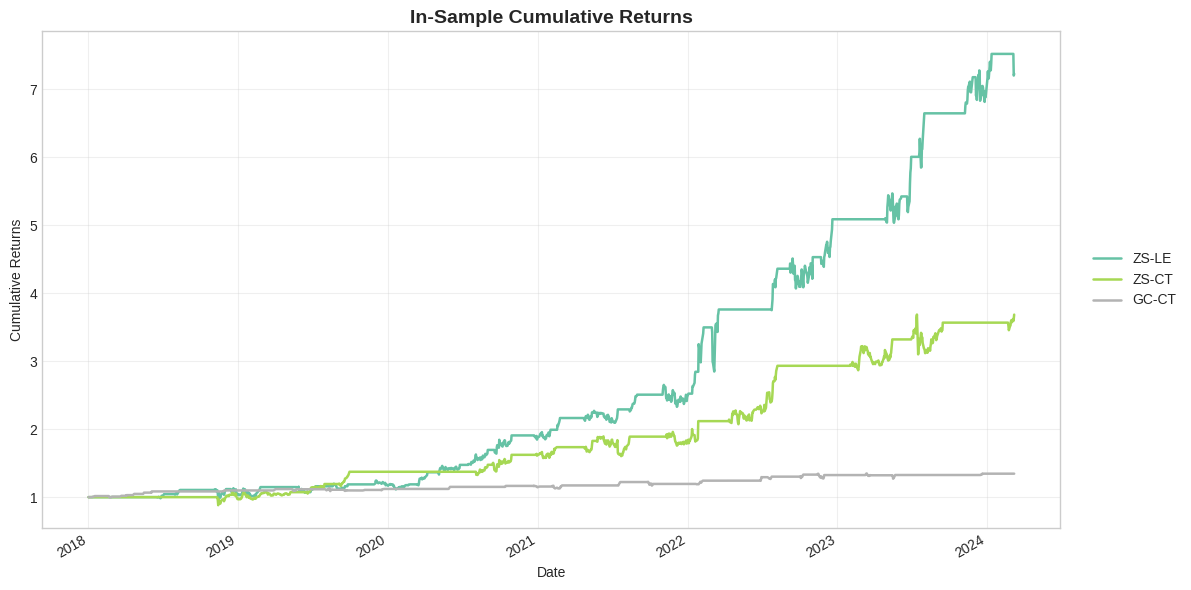

In [8]:
# Plot in-sample cumulative returns (better colors)
if len(ret) > 0:
    fig, ax = plt.subplots(figsize=(12, 6))
    ret.plot(ax=ax, linewidth=1.8, colormap='Set2')
    ax.set_title('In-Sample Cumulative Returns', fontsize=14, fontweight='bold')
    ax.set_ylabel('Cumulative Returns')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('insample_returns.png', dpi=150, bbox_inches='tight')
    plt.show()


In [9]:
# Performance stats (ffn — same as original)
if len(ret) > 0:
    perf = ret.calc_stats()
    perf.display()


Stat                 ZS-LE       ZS-CT       GC-CT
-------------------  ----------  ----------  ----------
Start                2018-01-02  2018-01-02  2018-01-02
End                  2024-03-07  2024-03-07  2024-03-07
Risk-free rate       0.00%       0.00%       0.00%

Total Return         622.45%     268.38%     34.51%
Daily Sharpe         1.51        1.15        0.90
Daily Sortino        2.43        1.76        1.55
CAGR                 37.73%      23.50%      4.92%
Max Drawdown         -18.56%     -15.88%     -5.74%
Calmar Ratio         2.03        1.48        0.86

MTD                  -3.90%      2.30%       0.00%
3m                   5.60%       3.30%       1.47%
6m                   8.74%       6.51%       1.47%
YTD                  4.45%       3.30%       0.00%
1Y                   42.04%      16.71%      1.53%
3Y (ann.)            49.50%      28.55%      4.69%
5Y (ann.)            44.45%      27.84%      4.13%
10Y (ann.)           -           -           -
Since Incep. (ann.)

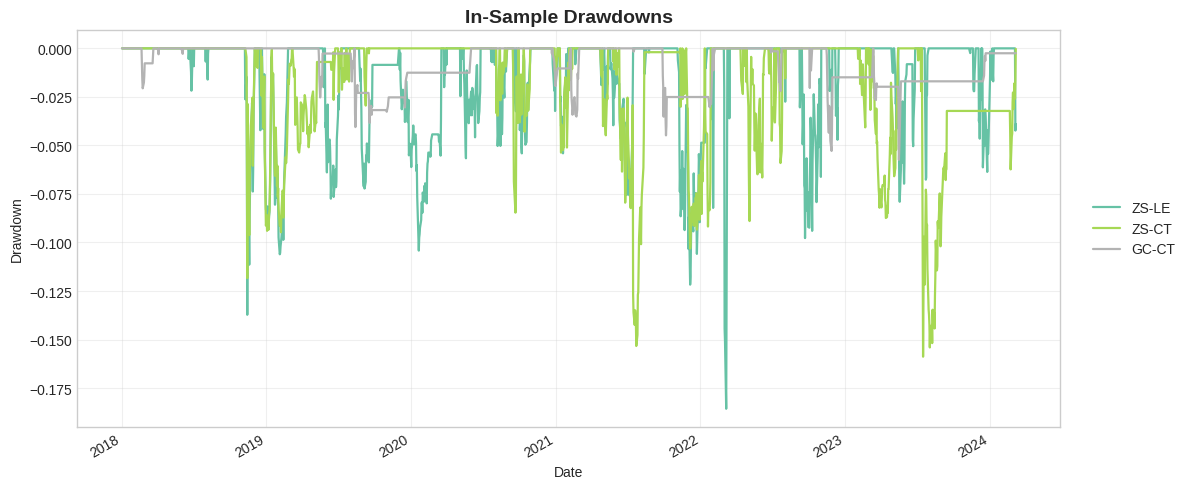

In [10]:
# Drawdowns
if len(ret) > 0:
    fig, ax = plt.subplots(figsize=(12, 5))
    ffn.to_drawdown_series(ret).plot(ax=ax, linewidth=1.6, colormap='Set2')
    ax.set_title('In-Sample Drawdowns', fontsize=14, fontweight='bold')
    ax.set_ylabel('Drawdown')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('insample_drawdown.png', dpi=150, bbox_inches='tight')
    plt.show()


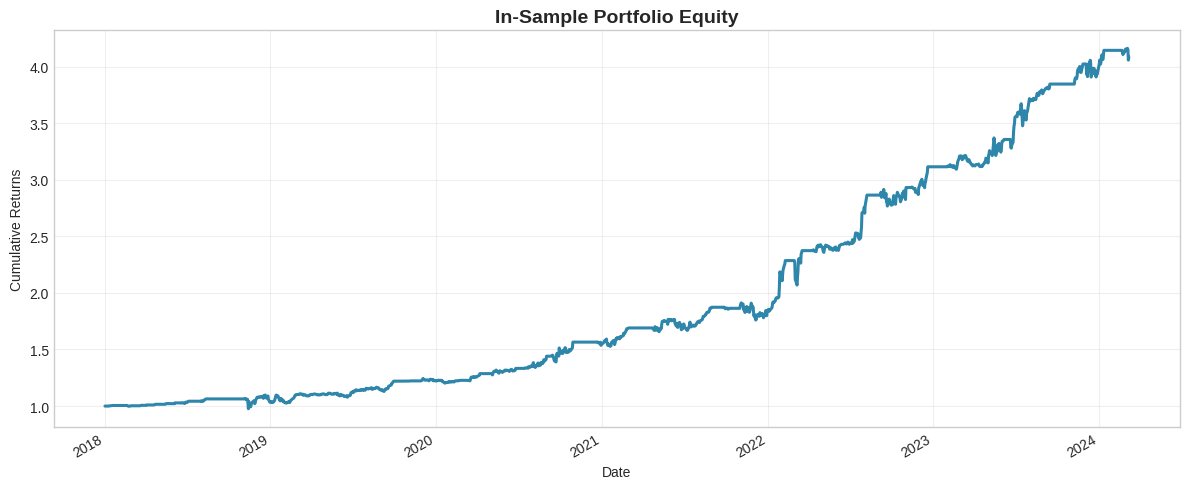

total_return    3.084469
cagr            0.255868
daily_sharpe    1.737702
max_drawdown   -0.094663
calmar          2.702922
dtype: object


In [11]:
# In-sample portfolio (equal weight)
if len(ret) > 0:
    port = ret.mean(axis=1)
    fig, ax = plt.subplots(figsize=(12, 5))
    port.plot(ax=ax, color=COLORS[0], linewidth=2.2)
    ax.set_title('In-Sample Portfolio Equity', fontsize=14, fontweight='bold')
    ax.set_ylabel('Cumulative Returns')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('insample_portfolio.png', dpi=150, bbox_inches='tight')
    plt.show()
    perf = port.calc_stats()
    print(perf.stats[['total_return','cagr','daily_sharpe','max_drawdown','calmar']])


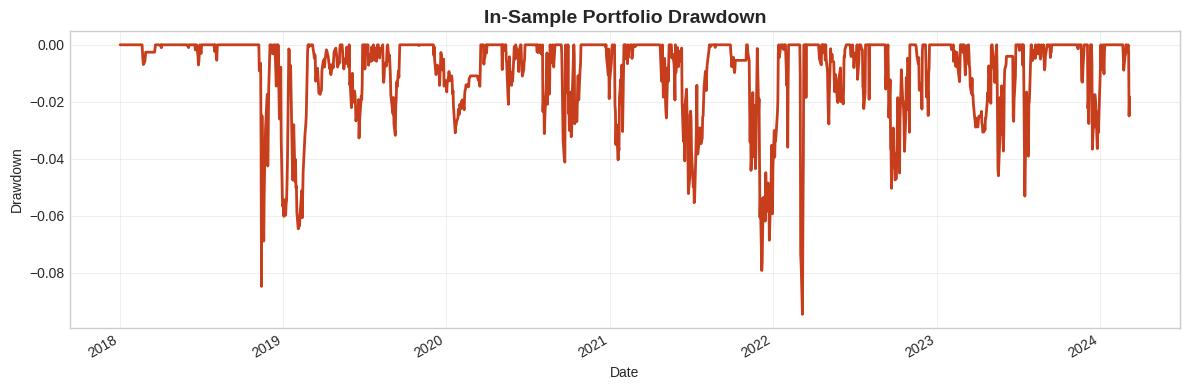

In [12]:
# Portfolio drawdown
if len(ret) > 0:
    fig, ax = plt.subplots(figsize=(12, 4))
    ffn.to_drawdown_series(port).plot(ax=ax, color=COLORS[3], linewidth=2)
    ax.set_title('In-Sample Portfolio Drawdown', fontsize=14, fontweight='bold')
    ax.set_ylabel('Drawdown')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## Out Sample Backtesting

In [13]:
# Out-sample testing on selected pairs
test_ret = pd.DataFrame()
for s1, s2, *_ in list_sect:
    name = f"{s1}-{s2}"
    try:
        cum, sharpe, hl = backtest(s1, s2, test[s1], test[s2])
        test_ret[name] = cum
    except Exception:
        continue

if len(test_ret) > 0:
    test_ret.iloc[0] = 1
    test_ret.index = test.index[:len(test_ret)]
    print(f"Out-sample pairs: {test_ret.shape[1]}")
    test_ret.tail(3)
else:
    print("No out-sample results")


Out-sample pairs: 3


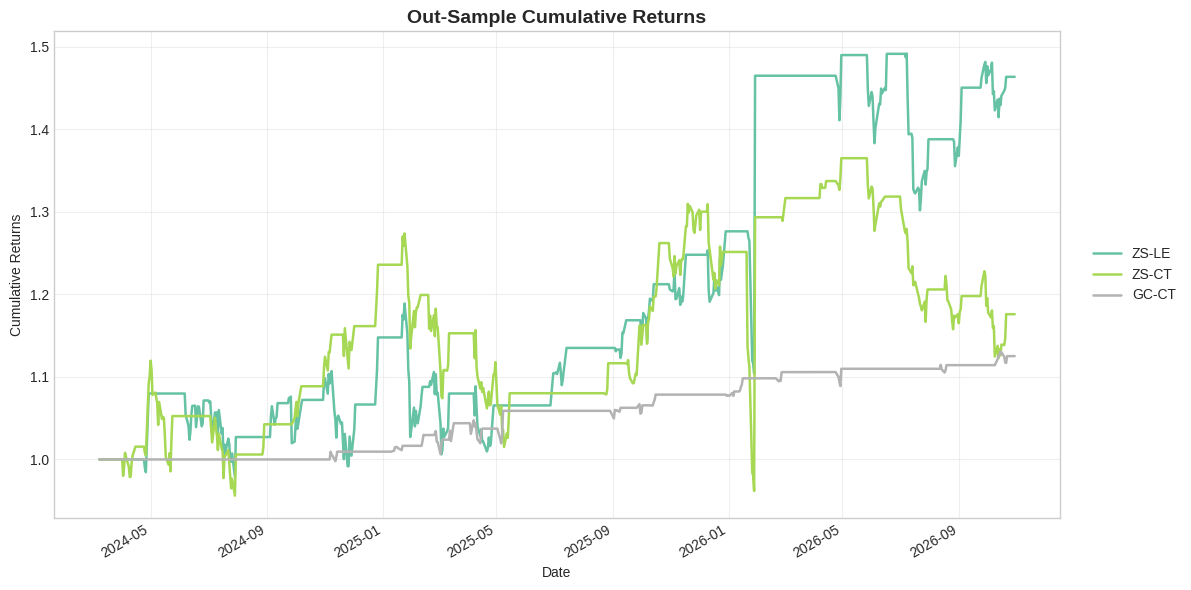

In [14]:
# Out-sample cumulative returns
if len(test_ret) > 0:
    fig, ax = plt.subplots(figsize=(12, 6))
    test_ret.plot(ax=ax, linewidth=1.8, colormap='Set2')
    ax.set_title('Out-Sample Cumulative Returns', fontsize=14, fontweight='bold')
    ax.set_ylabel('Cumulative Returns')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('outsample_returns.png', dpi=150, bbox_inches='tight')
    plt.show()


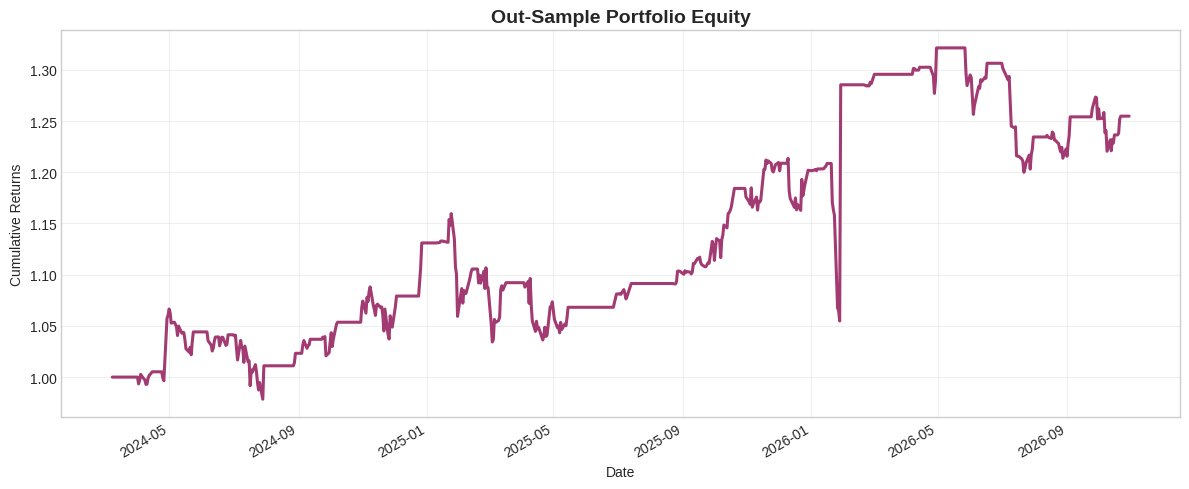

total_return    0.254768
cagr            0.089601
daily_sharpe    0.545034
max_drawdown    -0.13083
calmar          0.684864
dtype: object


In [15]:
# Out-sample portfolio
if len(test_ret) > 0:
    port_out = test_ret.mean(axis=1)
    fig, ax = plt.subplots(figsize=(12, 5))
    port_out.plot(ax=ax, color=COLORS[1], linewidth=2.2)
    ax.set_title('Out-Sample Portfolio Equity', fontsize=14, fontweight='bold')
    ax.set_ylabel('Cumulative Returns')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('outsample_portfolio.png', dpi=150, bbox_inches='tight')
    plt.show()
    perf = port_out.calc_stats()
    print(perf.stats[['total_return','cagr','daily_sharpe','max_drawdown','calmar']])


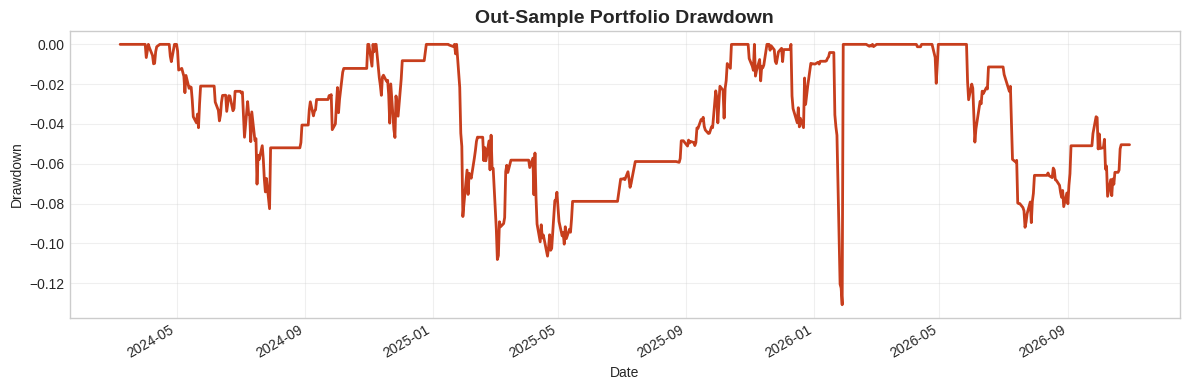

In [16]:
# Out-sample portfolio drawdown
if len(test_ret) > 0:
    fig, ax = plt.subplots(figsize=(12, 4))
    ffn.to_drawdown_series(port_out).plot(ax=ax, color=COLORS[3], linewidth=2)
    ax.set_title('Out-Sample Portfolio Drawdown', fontsize=14, fontweight='bold')
    ax.set_ylabel('Drawdown')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('outsample_drawdown.png', dpi=150, bbox_inches='tight')
    plt.show()
